# Basics of Linear Algebra

Linear algebra is the branch of mathematics that deals with vectors, matrices, and operations on them.
In R, you can easily perform matrix calculations, which are the backbone of statistics (regression), data science (PCA) and machine learning (neural networks).

Key concepts:
- **Vector**: A sequence of numbers (1D)
- **Matrix**: A rectangular arrangement of numbers (2D)
- **Operations**: addition, scalar multiplication, matrix multiplication, transpose, determinant, inverse, eigen-decomposition

In [1]:
# Notebook setup: wide, readable figures with an opaque white background.
# (Without the hook, base-R plots render with a transparent background and
#  the black axes/labels disappear on dark-themed notebook viewers.)
options(repr.plot.width = 10, repr.plot.height = 6, repr.plot.res = 100)
setHook("before.plot.new", function() par(bg = "white"))

## 1. Creating Matrices

`matrix()` fills values **column by column** by default. Use `byrow = TRUE` to fill row by row.

In [2]:
A <- matrix(c(1, 2, 3, 4, 5, 6), nrow = 2, ncol = 3)  # 2x3 matrix (filled by column)
B <- matrix(c(6, 5, 4, 3, 2, 1), nrow = 2, ncol = 3)  # 2x3 matrix

print("Matrix A:"); print(A)
print("Matrix B:"); print(B)
cat("dim(A) =", dim(A), "\n")

[1] "Matrix A:"


     [,1] [,2] [,3]
[1,]    1    3    5
[2,]    2    4    6


[1] "Matrix B:"


     [,1] [,2] [,3]
[1,]    6    4    2
[2,]    5    3    1


dim(A) = 2 3 


## 2. Element-wise Operations

Addition, subtraction and scalar multiplication work element by element and require **equal dimensions**:

$$
(A + B)_{ij} = A_{ij} + B_{ij}, \qquad (cA)_{ij} = c\,A_{ij}
$$

In [3]:
print("Matrix Addition (A + B):");      print(A + B)
print("Scalar Multiplication (2 * A):"); print(2 * A)
print("Element-wise product (A * B) - NOT matrix multiplication:"); print(A * B)

[1] "Matrix Addition (A + B):"


     [,1] [,2] [,3]
[1,]    7    7    7
[2,]    7    7    7


[1] "Scalar Multiplication (2 * A):"


     [,1] [,2] [,3]
[1,]    2    6   10
[2,]    4    8   12


[1] "Element-wise product (A * B) - NOT matrix multiplication:"


     [,1] [,2] [,3]
[1,]    6   12   10
[2,]   10   12    6


## 3. Matrix Multiplication

For $A$ ($m \times n$) and $D$ ($n \times p$), the product $AD$ is $m \times p$:

$$
(AD)_{ij} = \sum_{k=1}^{n} A_{ik} D_{kj}
$$

In R this is `%*%`. Note that matrix multiplication is **not commutative**: in general $AD \neq DA$.

In [4]:
D <- matrix(c(1, 0, 0, 1, 1, 1), nrow = 3, ncol = 2) # 3x2 matrix
print("D:"); print(D)

C_mult <- A %*% D
print("Matrix Multiplication (A %*% D), a 2x2 result:"); print(C_mult)

print("D %*% A is 3x3 - a completely different matrix:"); print(D %*% A)

# Check one entry manually: row 1 of A times column 2 of D
cat("Manual (AD)[1,2] =", sum(A[1, ] * D[, 2]), "\n")

[1] "D:"


     [,1] [,2]
[1,]    1    1
[2,]    0    1
[3,]    0    1


[1] "Matrix Multiplication (A %*% D), a 2x2 result:"


     [,1] [,2]
[1,]    1    9
[2,]    2   12


[1] "D %*% A is 3x3 - a completely different matrix:"


     [,1] [,2] [,3]
[1,]    3    7   11
[2,]    2    4    6
[3,]    2    4    6


Manual (AD)[1,2] = 9 


In [5]:
# Transpose: rows become columns
print("Transpose of A:"); print(t(A))
cat("Property (AD)^T == D^T A^T :", all.equal(t(A %*% D), t(D) %*% t(A)), "\n")

[1] "Transpose of A:"


     [,1] [,2]
[1,]    1    2
[2,]    3    4
[3,]    5    6


Property (AD)^T == D^T A^T : TRUE 


## 4. Determinant and Inverse

For a square matrix $E$, the inverse $E^{-1}$ satisfies $E E^{-1} = I$. It exists only if $\det(E) \neq 0$. For a $2\times2$ matrix:

$$
E = \begin{pmatrix} a & b \\ c & d \end{pmatrix}, \quad \det(E) = ad - bc, \quad E^{-1} = \frac{1}{ad-bc}\begin{pmatrix} d & -b \\ -c & a \end{pmatrix}
$$

In [6]:
E <- matrix(c(4, 7, 2, 6), nrow = 2, ncol = 2)
print("E:"); print(E)
cat("Determinant of E:", det(E), "\n")

inv_E <- solve(E)
print("Inverse of E:"); print(inv_E)
print("E %*% E^-1 (should be the identity):"); print(round(E %*% inv_E, 10))

singular <- matrix(c(1, 2, 2, 4), 2)   # second column = 2 x first column
cat("\ndet(singular) =", det(singular), "-> no inverse exists\n")
res <- tryCatch(solve(singular), error = function(e) conditionMessage(e))
cat("solve(singular) error:", res, "\n")

[1] "E:"


     [,1] [,2]
[1,]    4    2
[2,]    7    6


Determinant of E: 10 


[1] "Inverse of E:"


     [,1] [,2]
[1,]  0.6 -0.2
[2,] -0.7  0.4


[1] "E %*% E^-1 (should be the identity):"


     [,1] [,2]
[1,]    1    0
[2,]    0    1



det(singular) = 0 -> no inverse exists


solve(singular) error: Lapack routine dgesv: system is exactly singular: U[2,2] = 0 


## 5. Matrices as Transformations

A $2\times2$ matrix **moves points in the plane**. Multiplying every corner of the unit square by a matrix shows how the matrix stretches, rotates or shears space. The absolute value of the determinant equals the **area scale factor**.

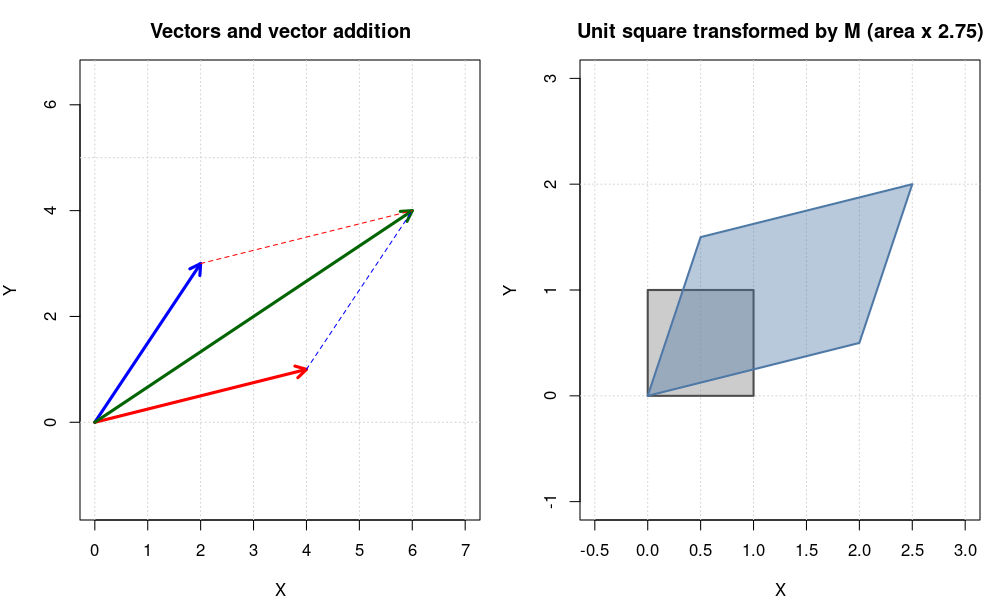

In [7]:
square <- matrix(c(0, 0,  1, 0,  1, 1,  0, 1), nrow = 2)   # corners as columns
M <- matrix(c(2, 0.5, 0.5, 1.5), 2)                         # a stretch + shear
transformed <- M %*% square

par(mfrow = c(1, 2), mar = c(4, 4, 3, 1))

# Left: two vectors and their sum (parallelogram rule)
v1 <- c(2, 3); v2 <- c(4, 1); s <- v1 + v2
plot(NA, xlim = c(0, 7), ylim = c(0, 5), asp = 1, xlab = "X", ylab = "Y",
     main = "Vectors and vector addition")
grid()
arrows(0, 0, v1[1], v1[2], col = "blue", lwd = 3, length = 0.12)
arrows(0, 0, v2[1], v2[2], col = "red", lwd = 3, length = 0.12)
arrows(0, 0, s[1], s[2], col = "darkgreen", lwd = 3, length = 0.12)
segments(v1[1], v1[2], s[1], s[2], lty = 2, col = "red")
segments(v2[1], v2[2], s[1], s[2], lty = 2, col = "blue")
legend("topleft", c("v1 = (2,3)", "v2 = (4,1)", "v1 + v2 = (6,4)"),
       col = c("blue", "red", "darkgreen"), lwd = 3, bty = "n")

# Right: unit square before/after M
plot(NA, xlim = c(-0.5, 3), ylim = c(-0.5, 2.5), asp = 1, xlab = "X", ylab = "Y",
     main = sprintf("Unit square transformed by M (area x %.2f)", abs(det(M))))
grid()
polygon(square[1, ], square[2, ], col = adjustcolor("grey60", 0.5), border = "grey30", lwd = 2)
polygon(transformed[1, ], transformed[2, ], col = adjustcolor("#4E79A7", 0.4), border = "#4E79A7", lwd = 2)
legend("topleft", c("original (area 1)", "M %*% square"), fill = c(adjustcolor("grey60", 0.5),
       adjustcolor("#4E79A7", 0.4)), bty = "n")

## 6. Eigenvalues and Eigenvectors

An eigenvector $\mathbf{v}$ of $M$ is a direction that the matrix only **stretches**, never rotates:

$$
M\mathbf{v} = \lambda \mathbf{v}
$$

$\lambda$ is the stretch factor (eigenvalue). Eigen-decomposition is the engine behind **PCA** (Section 05).

In [8]:
eig <- eigen(M)
print(eig)
v <- eig$vectors[, 1]; lambda <- eig$values[1]
cat("Check M v       :", round(M %*% v, 4), "\n")
cat("Check lambda * v:", round(lambda * v, 4), "\n")
cat("Product of eigenvalues =", prod(eig$values), "= det(M) =", det(M), "\n")

eigen() decomposition
$values
[1] 2.309017 1.190983

$vectors
           [,1]       [,2]
[1,] -0.8506508  0.5257311
[2,] -0.5257311 -0.8506508



Check M v       : -1.9642 -1.2139 


Check lambda * v: -1.9642 -1.2139 


Product of eigenvalues = 2.75 = det(M) = 2.75 


*Insight: Three facts tie this lesson together: $|\det(M)|$ is how much $M$ scales area, $\det(M)=0$ means $M$ squashes space flat (so it can't be undone → no inverse), and the determinant equals the product of the eigenvalues.*

## Real-World Use Case or Analogy

- **Vectors**: arrows showing both direction and length — like a wind forecast (speed + direction).
- **Matrices**: spreadsheets of numbers where rows and columns matter.
- **Matrix multiplication**: combining transformations — like applying "rotate" then "resize" to a photo in an editor.
- **Determinant**: tells you whether a transformation can be reversed; a zero determinant is like a photo squashed to a single line — the original can't be recovered.
- **Inverse**: the "undo" button for a transformation.
- **Eigenvectors**: the grain of a piece of wood — the directions along which it naturally stretches.

Linear algebra is the mathematical engine behind 3D graphics, recommendation systems, and every neural network you'll train later in this course.